# Malha aérea doméstica brasileira (ANAC 2025)

**Pergunta:** quais aeroportos atuam como gargalos críticos na malha nacional e qual o impacto real da interrupção de um hub regional no isolamento do país?

**Decisão prática atrelada:** orientar planos de contingência governamentais e a alocação estratégica de investimentos em infraestrutura aeroportuária regional.

**Recorte:** voo doméstico (Brasil→Brasil), `DECOLAGENS > 0`, sem self-loop, agregado por par no ano.

Notebook único da entrega: modelagem → análise → resposta.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd

RAIZ = Path.cwd().resolve()
while not (RAIZ / "data" / "2025.csv").exists():
    if RAIZ == RAIZ.parent:
        raise FileNotFoundError("rode o notebook de dentro do repositório do projeto")
    RAIZ = RAIZ.parent

sys.path.insert(0, str(RAIZ / "src"))
import malha as M  # noqa: E402

FIGURAS = RAIZ / "figuras"
RESULTADOS = RAIZ / "resultados"
FIGURAS.mkdir(exist_ok=True)
RESULTADOS.mkdir(exist_ok=True)

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "font.size": 10, "axes.grid": True,
                     "grid.alpha": 0.3, "axes.axisbelow": True})
pd.set_option("display.width", 200)
regioes = {"NORTE": "#2ca02c", "NORDESTE": "#ff7f0e", "CENTRO-OESTE": "#8c564b",
           "SUDESTE": "#1f77b4", "SUL": "#d62728"}
print("raiz do projeto:", RAIZ.name)

raiz do projeto: air-traffic-brazil


## 1. Modelagem: do dado à rede

- **Nó:** aeródromo (sigla ICAO). **Aresta dirigida:** rota doméstica origem → destino.
- **Pesos:** `decolagens` e `passageiros`; distância em km (haversine) como atributo.
- **Direção:** `DiGraph`, porque os volumes de ida e volta diferem; a projeção não dirigida só é usada nas ferramentas que a exigem.

In [2]:
bruto = M.carregar_bruto()
voos = M.recortar(bruto)
rotas = M.agregar_rotas(voos)
g = M.construir_digrafo(rotas)
h = M.grafo_nao_dirigido(g)

print(f"bruto: {len(bruto)} linhas x {bruto.shape[1]} colunas")
print(f"recorte canônico: {len(rotas)} rotas | {g.number_of_nodes()} aeródromos | "
      f"{g.number_of_edges()} arestas dirigidas")
print(f"projeção não dirigida: {h.number_of_edges()} arestas simples")

bruto: 37988 linhas x 38 colunas
recorte canônico: 1660 rotas | 176 aeródromos | 1660 arestas dirigidas
projeção não dirigida: 987 arestas simples


Antes de fixar o recorte, medimos o efeito de cada decisão alternativa: quanto do resultado é o dado e quanto é a escolha.

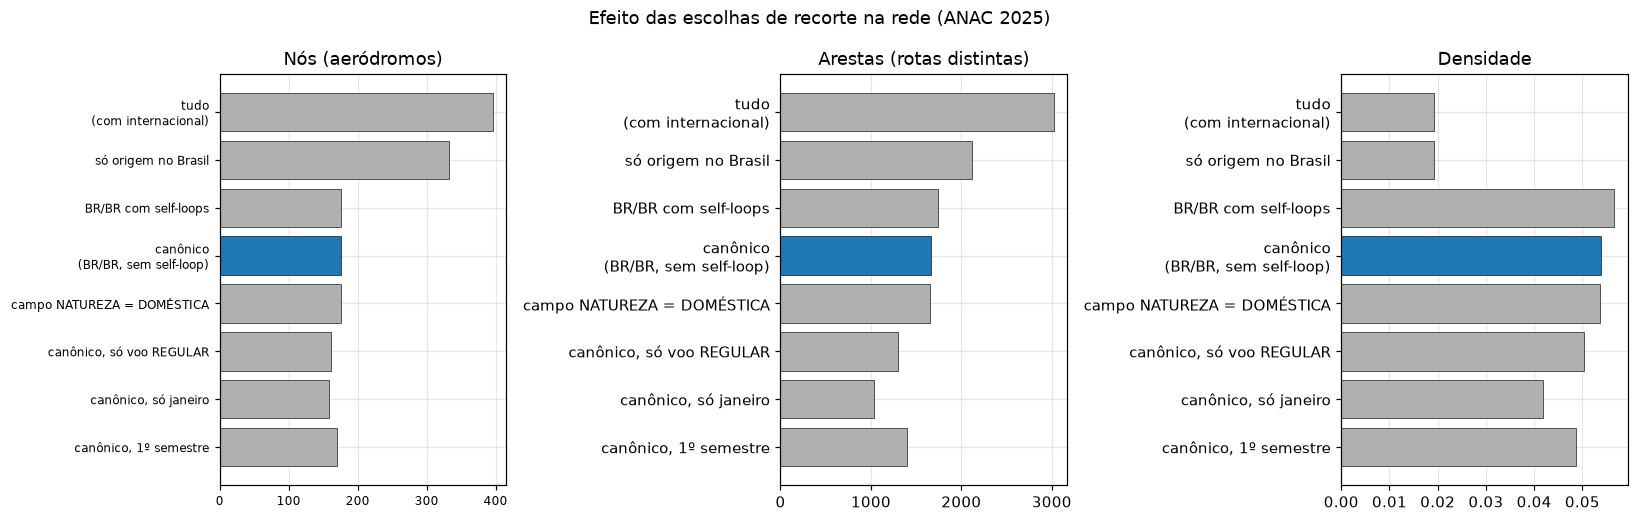

,recorte,linhas,nos,arestas,densidade,fracao_decolagens
0,tudo (com internacional),34157,396,3020,0.01931,1.0000
1,só origem no Brasil,26922,333,2119,0.01917,0.9045
2,BR/BR com self-loops,23091,176,1744,0.05662,0.8258
3,"canônico (BR/BR, sem self-loop)",22128,176,1660,0.05390,0.8217
4,campo NATUREZA = DOMÉSTICA,21594,176,1654,0.05370,0.8201
5,"canônico, só voo REGULAR",14969,161,1299,0.05043,0.7928
6,"canônico, só janeiro",2069,158,1039,0.04189,0.0720
7,"canônico, 1º semestre",11163,170,1396,0.04859,0.4041


In [3]:
tabela_recortes = M.tabela_alternativas_recorte(bruto)
tabela_recortes.to_csv(RESULTADOS / "tabela_recortes.csv", index=False)

visao = tabela_recortes[["recorte", "linhas", "nos", "arestas", "densidade", "fracao_decolagens"]].copy()
visao["densidade"] = visao["densidade"].round(5)
visao["fracao_decolagens"] = visao["fracao_decolagens"].round(4)

fig, eixos = plt.subplots(1, 3, figsize=(15, 4.8))
rotulos = tabela_recortes["recorte"].str.replace(" (", "\n(", regex=False)
cores = ["#b0b0b0"] * len(rotulos)
cores[3] = "#1f77b4"  # recorte canônico destacado
for eixo, coluna, titulo in zip(eixos, ["nos", "arestas", "densidade"],
                                ["Nós (aeródromos)", "Arestas (rotas distintas)", "Densidade"]):
    eixo.barh(rotulos, tabela_recortes[coluna], color=cores, edgecolor="black", linewidth=0.4)
    eixo.set_title(titulo)
    eixo.invert_yaxis()
eixos[0].tick_params(labelsize=8)
fig.suptitle("Efeito das escolhas de recorte na rede (ANAC 2025)", fontsize=12)
fig.tight_layout()
fig.savefig(FIGURAS / "01_efeito_dos_recortes.png", bbox_inches="tight")
plt.show()
visao

In [4]:
decisoes = pd.DataFrame([
    dict(decisao="Janela temporal", alternativas="ano de 2025 × mês × semestre",
         escolha="ano de 2025 (12 meses)",
         porque="conectividade estrutural; mês único perde 18 aeródromos", efeito="176 nós e 1.660 rotas"),
    dict(decisao="Malha doméstica", alternativas="tudo × só origem BR × BR/BR",
         escolha="origem e destino no Brasil (PAÍS)",
         porque="a pergunta é doméstica", efeito="396 -> 176 nós"),
    dict(decisao="Campo de domesticidade", alternativas="PAÍS das pontas × NATUREZA (ANAC)",
         escolha="PAÍS das pontas",
         porque="NATUREZA marca rotas internas como INTERNACIONAL", efeito="diferença de 6 rotas"),
    dict(decisao="Self-loops", alternativas="manter × remover origem = destino",
         escolha="remover",
         porque="aeroporto não é rota para si mesmo", efeito="1.744 -> 1.660 arestas"),
    dict(decisao="Tipo de voo", alternativas="todos os grupos × só REGULAR",
         escolha="todos os grupos",
         porque="a rota existiu; só regular derrubaria 15 aeródromos", efeito="3,5% das decolagens"),
    dict(decisao="Rota ativa", alternativas="DECOLAGENS > 0 × PASSAGEIROS > 0",
         escolha="DECOLAGENS > 0",
         porque="mede decolagens (o voo aconteceu)", efeito="37.988 -> 34.157 linhas ativas"),
])
decisoes.to_csv(RESULTADOS / "decisoes_recorte.csv", index=False)
decisoes

,decisao,alternativas,escolha,porque,efeito
0,Janela temporal,ano de 2025 × mês × semestre,ano de 2025 (12 meses),conectividade estrutural; mês único perde 18 a...,176 nós e 1.660 rotas
1,Malha doméstica,tudo × só origem BR × BR/BR,origem e destino no Brasil (PAÍS),a pergunta é doméstica,396 -> 176 nós
2,Campo de domesticidade,PAÍS das pontas × NATUREZA (ANAC),PAÍS das pontas,NATUREZA marca rotas internas como INTERNACIONAL,diferença de 6 rotas
3,Self-loops,manter × remover origem = destino,remover,aeroporto não é rota para si mesmo,1.744 -> 1.660 arestas
4,Tipo de voo,todos os grupos × só REGULAR,todos os grupos,a rota existiu; só regular derrubaria 15 aeród...,"3,5% das decolagens"
5,Rota ativa,DECOLAGENS > 0 × PASSAGEIROS > 0,DECOLAGENS > 0,mede decolagens (o voo aconteceu),37.988 -> 34.157 linhas ativas


## 2. Estrutura da malha: densidade, grau e volume

In [5]:
metricas = M.metricas_basicas(g)
reciprocas = sum(1 for u, v in g.edges() if g.has_edge(v, u)) / 2
print(f"nós: {metricas['nos']} | arestas: {metricas['arestas']}")
print(f"densidade: {metricas['densidade']:.4f} | grau médio: {metricas['grau_medio']:.2f} | "
      f"grau máximo: {metricas['grau_maximo']} | mínimo: {metricas['grau_minimo']}")
print(f"pares com rota nas duas direções: {reciprocas:.0f} de {h.number_of_edges()} "
      f"({100 * reciprocas / h.number_of_edges():.1f}%)")

nós: 176 | arestas: 1660
densidade: 0.0539 | grau médio: 18.86 | grau máximo: 181 | mínimo: 1
pares com rota nas duas direções: 673 de 987 (68.2%)


Rede **esparsa** (densidade 0,054) e de **cauda longa**: o grau médio não descreve aeródromo nenhum. A reciprocidade (68%) confirma que o `DiGraph` não é decorativo: 314 pares têm rota em um sentido só.

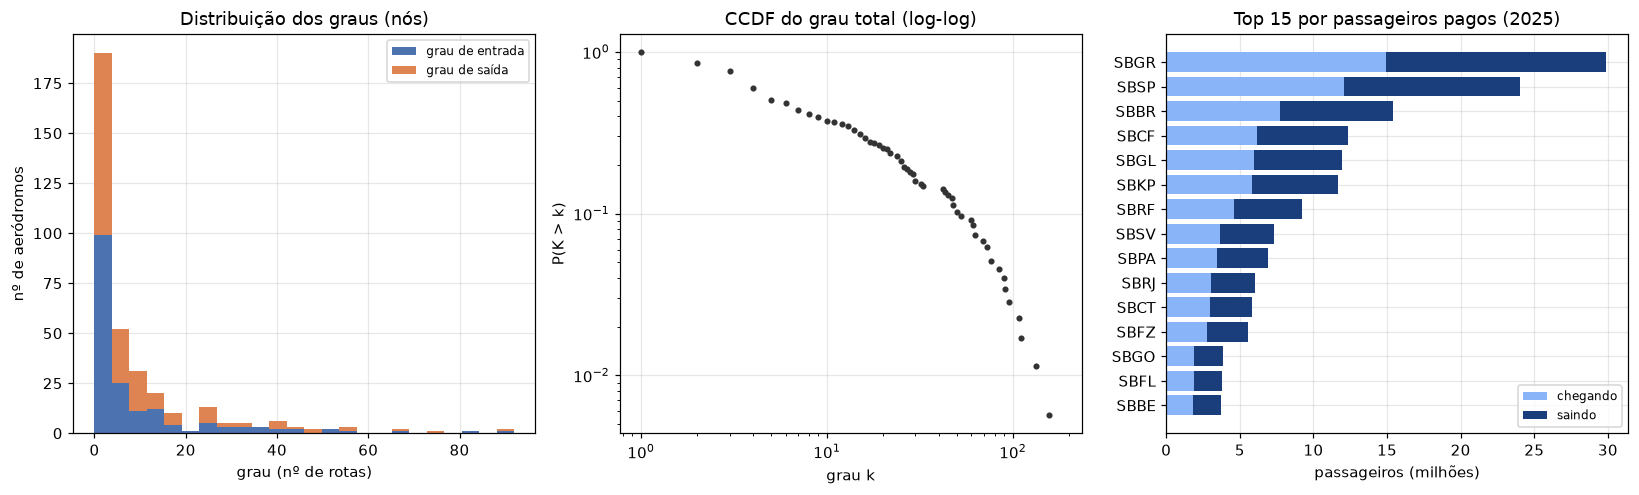

grau total mediano: 6.0
aeródromos com grau total <= 4: 71


,icao,nome,uf,grau_entrada,grau_saida,grau_total,passageiros_total
0,SBGR,GUARULHOS,SP,67,67,134,29872406.0
1,SBSP,SÃO PAULO,SP,57,54,111,24043265.0
2,SBBR,BRASÍLIA,DF,43,48,91,15390238.0
3,SBCF,CONFINS,MG,81,75,156,12339499.0
4,SBGL,RIO DE JANEIRO,RJ,50,45,95,11928249.0
5,SBKP,CAMPINAS,SP,92,89,181,11654910.0
6,SBRF,RECIFE,PE,53,55,108,9242285.0
7,SBSV,SALVADOR,BA,37,39,76,7304233.0
8,SBPA,PORTO ALEGRE,RS,31,30,61,6928031.0
9,SBRJ,RIO DE JANEIRO,RJ,13,19,32,6046310.0


In [6]:
graus = M.tabela_graus(g)
graus.to_csv(RESULTADOS / "graus.csv", index=False)

fig, eixos = plt.subplots(1, 3, figsize=(15, 4.6))
eixos[0].hist([graus.grau_entrada, graus.grau_saida], bins=24, stacked=True,
              label=["grau de entrada", "grau de saída"], color=["#4c72b0", "#dd8452"])
eixos[0].set_title("Distribuição dos graus (nós)")
eixos[0].set_xlabel("grau (nº de rotas)"); eixos[0].set_ylabel("nº de aeródromos")
eixos[0].legend(fontsize=8)
x_ccdf, y_ccdf = M.ccdf(graus.grau_total)
eixos[1].loglog(x_ccdf, y_ccdf, marker="o", markersize=3, linestyle="none", color="#333333")
eixos[1].set_title("CCDF do grau total (log-log)")
eixos[1].set_xlabel("grau k"); eixos[1].set_ylabel("P(K > k)")
top15 = graus.head(15).iloc[::-1]
eixos[2].barh(top15.icao, top15.passageiros_entrada / 1e6, label="chegando", color="#8ab4f8")
eixos[2].barh(top15.icao, top15.passageiros_saida / 1e6, left=top15.passageiros_entrada / 1e6,
              label="saindo", color="#1a3d7c")
eixos[2].set_title("Top 15 por passageiros pagos (2025)")
eixos[2].set_xlabel("passageiros (milhões)"); eixos[2].legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIGURAS / "02_graus_e_hubs.png", bbox_inches="tight")
plt.show()

print("grau total mediano:", graus.grau_total.median())
print("aeródromos com grau total <= 4:", (graus.grau_total <= 4).sum())
graus.head(10)[["icao", "nome", "uf", "grau_entrada", "grau_saida", "grau_total", "passageiros_total"]]

Grau e volume medem coisas diferentes: **SBKP** lidera em grau (181), **SBGR** em passageiros (29,9 mi). A cauda é grande: metade dos aeródromos tem grau total ≤ 6.

## 3. Alcance e fragmentação

BFS mede quantos saltos separam cada aeródromo de uma semente; os componentes dizem o que cai junto quando a rede se parte.

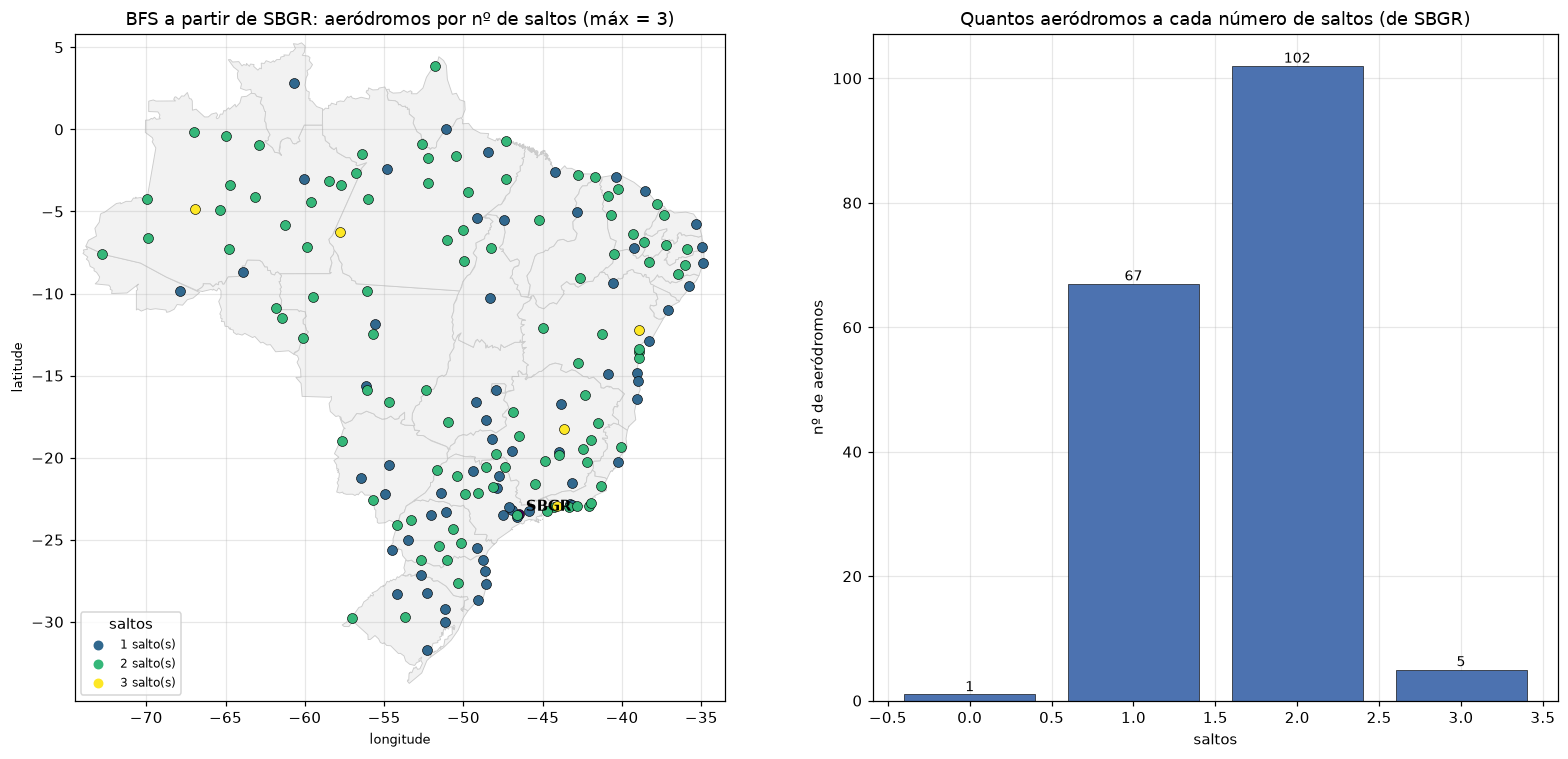

alcançáveis a partir de SBGR: 175 de 176
distância média de SBGR: 1.63 saltos | pior caso: 3
em até 2 saltos: 170 aeródromos (97%)


In [7]:
niveis = M.camadas_bfs(g, "SBGR")
por_nivel = pd.Series(niveis).value_counts().sort_index()

fig, eixos = plt.subplots(1, 2, figsize=(15, 7), gridspec_kw={"width_ratios": [1.25, 1]})
M.fundo_mapa(eixos[0])
pos = M.posicoes(g)
cmap = plt.get_cmap("viridis")
nivel_max = max(niveis.values())
for n, nivel in niveis.items():
    eixos[0].scatter(*pos[n], color=cmap(nivel / nivel_max), s=42, edgecolor="black", linewidth=0.4, zorder=3)
eixos[0].annotate("SBGR", (pos["SBGR"][0] + 0.4, pos["SBGR"][1] + 0.2), fontweight="bold")
eixos[0].set_xlim(-74.5, -33.5); eixos[0].set_ylim(-34.8, 5.8); eixos[0].set_aspect(1.035)
eixos[0].set_title(f"BFS a partir de SBGR: aeródromos por nº de saltos (máx = {nivel_max})")
eixos[0].set_xlabel("longitude"); eixos[0].set_ylabel("latitude")
for nivel in range(1, nivel_max + 1):
    eixos[0].scatter([], [], color=cmap(nivel / nivel_max), label=f"{nivel} salto(s)", s=30)
eixos[0].legend(fontsize=8, loc="lower left", title="saltos")
eixos[1].bar(por_nivel.index, por_nivel.values, color="#4c72b0", edgecolor="black", linewidth=0.4)
for nivel, valor in por_nivel.items():
    eixos[1].annotate(str(valor), (nivel, valor), ha="center", va="bottom", fontsize=9)
eixos[1].set_title("Quantos aeródromos a cada número de saltos (de SBGR)")
eixos[1].set_xlabel("saltos"); eixos[1].set_ylabel("nº de aeródromos")
fig.tight_layout()
fig.savefig(FIGURAS / "03_bfs_camadas.png", bbox_inches="tight")
plt.show()

print(f"alcançáveis a partir de SBGR: {len(niveis)} de {g.number_of_nodes()}")
print(f"distância média de SBGR: {np.mean(list(niveis.values())):.2f} saltos | pior caso: {nivel_max}")
print(f"em até 2 saltos: {sum(v <= 2 for v in niveis.values())} aeródromos "
      f"({100 * sum(v <= 2 for v in niveis.values()) / g.number_of_nodes():.0f}%)")

A malha é de **mundo pequeno**: 97% dos aeródromos estão a ≤ 2 saltos de SBGR.

In [8]:
comp = M.resumo_componentes(g)
dist = M.distancia_e_eficiencia(g)
print(f"WCC: {comp['n_wcc']} (maior {comp['maior_wcc']}) | SCC: {comp['n_scc']} (maior {comp['maior_scc']})")
print(f"fora do maior SCC: {comp['fora_do_maior_scc']}")
print(f"comprimento médio: {dist['comprimento_medio_scc']:.2f} saltos | diâmetro: {dist['diametro_scc']} | raio: {dist['raio_scc']}")
print(f"centro: {len(dist['centro_scc'])} aeródromos | periferia: {len(dist['periferia_scc'])} ({', '.join(dist['periferia_scc'])})")
print(f"eficiência global: {dist['eficiencia_global']:.4f}")

WCC: 1 (maior 176) | SCC: 2 (maior 175)
fora do maior SCC: ['SBBP']
comprimento médio: 2.47 saltos | diâmetro: 5 | raio: 3
centro: 24 aeródromos | periferia: 9 (SBEK, SBIC, SDPA, SDTK, SNBC, SNDC, SSBZ, SWEI, SWGN)
eficiência global: 0.4404


**WCC** mede fragmentação, **SCC** mede retorno garantido; **eficiência global** (média de 1/d com par inalcançável = 0) é a régua que sobrevive à falha. A malha é um único componente fraco e quase inteiramente um SCC.

## 4. Centralidades: quem está no caminho

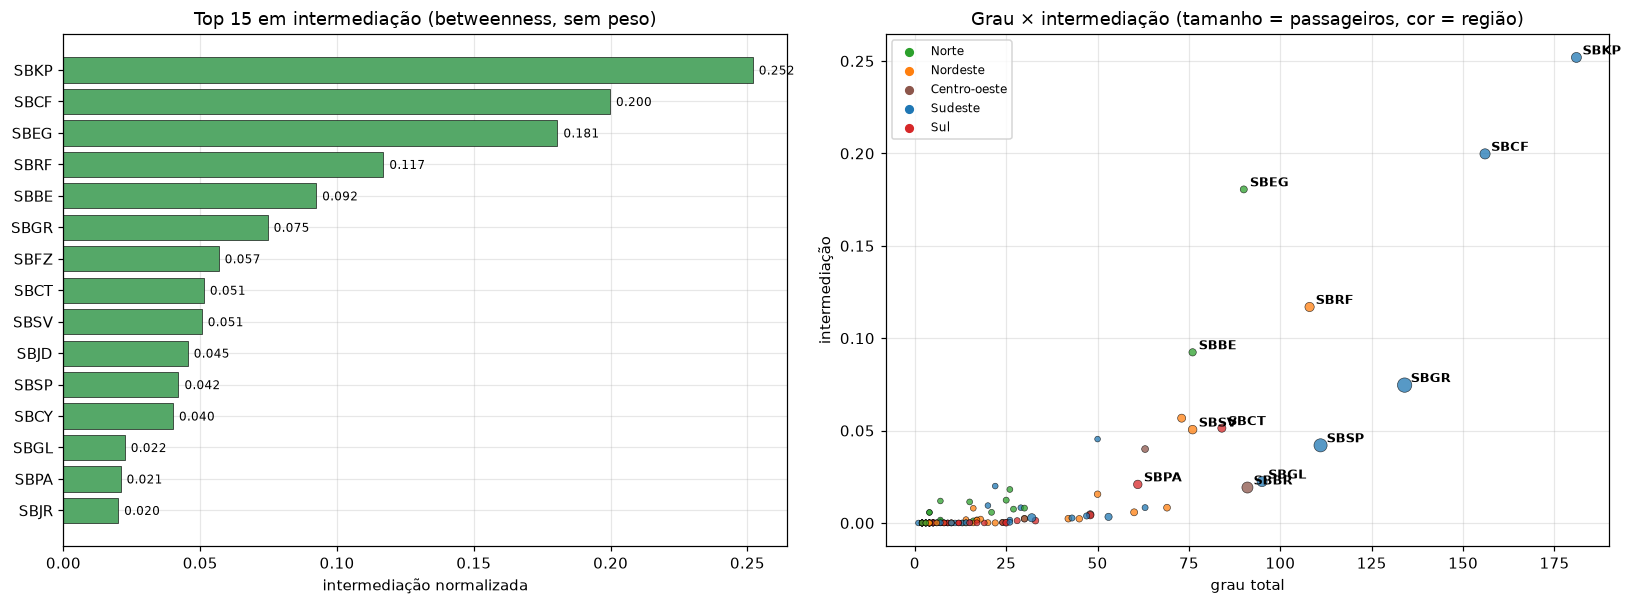

,icao,nome,uf,grau_total,passageiros_total,intermediacao,proximidade_entrada,autovetor_entrada
5,SBKP,CAMPINAS,SP,181,11654910.0,0.2519,0.6679,0.2665
4,SBCF,CONFINS,MG,156,12339499.0,0.1997,0.6458,0.2519
27,SBEG,MANAUS,AM,90,2961478.0,0.1805,0.5556,0.1449
1,SBRF,RECIFE,PE,108,9242285.0,0.1169,0.5719,0.2050
32,SBBE,BELÉM,PA,76,3714377.0,0.0923,0.5368,0.1363
17,SBGR,GUARULHOS,SP,134,29872406.0,0.0746,0.6055,0.2450
15,SBFZ,FORTALEZA,CE,73,5556875.0,0.0567,0.5319,0.1530
35,SBCT,SÃO JOSÉ DOS PINHAIS,PR,84,5846695.0,0.0513,0.5573,0.1856
21,SBSV,SALVADOR,BA,76,7304233.0,0.0505,0.5418,0.1744
11,SBJD,JUNDIAÍ,SP,50,0.0,0.0454,0.4667,0.1039


In [9]:
cent = M.tabela_centralidades(g)
cent.to_csv(RESULTADOS / "centralidades.csv", index=False)

fig, eixos = plt.subplots(1, 2, figsize=(15, 5.6))
ordem_b = cent.sort_values("intermediacao", ascending=False).head(15).iloc[::-1]
eixos[0].barh(ordem_b.icao, ordem_b.intermediacao, color="#55a868", edgecolor="black", linewidth=0.4)
for icao, valor in zip(ordem_b.icao, ordem_b.intermediacao):
    eixos[0].annotate(f"{valor:.3f}", (valor, icao), xytext=(4, -3), textcoords="offset points", fontsize=8)
eixos[0].set_title("Top 15 em intermediação (betweenness, sem peso)")
eixos[0].set_xlabel("intermediação normalizada")
eixos[1].scatter(cent.grau_total, cent.intermediacao, s=14 + cent.passageiros_total / 4e5,
                 c=[regioes[r] for r in cent.regiao], alpha=0.75, edgecolor="black", linewidth=0.4)
for icao in ["SBKP", "SBCF", "SBEG", "SBGR", "SBSP", "SBRF", "SBBE", "SBBR", "SBCT", "SBSV", "SBPA", "SBGL"]:
    linha = cent[cent.icao == icao].iloc[0]
    eixos[1].annotate(icao, (linha.grau_total, linha.intermediacao), xytext=(4, 2),
                      textcoords="offset points", fontsize=8.5, fontweight="bold")
eixos[1].set_title("Grau × intermediação (tamanho = passageiros, cor = região)")
eixos[1].set_xlabel("grau total"); eixos[1].set_ylabel("intermediação")
for regiao, cor in regioes.items():
    eixos[1].scatter([], [], color=cor, label=regiao.capitalize(), s=25)
eixos[1].legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIGURAS / "04_centralidades.png", bbox_inches="tight")
plt.show()

cent.sort_values("intermediacao", ascending=False).head(12)[
    ["icao", "nome", "uf", "grau_total", "passageiros_total", "intermediacao",
     "proximidade_entrada", "autovetor_entrada"]].round(4)

Os gargalos são **SBKP** (0,252), **SBCF** (0,200) e **SBEG** (0,181), não os maiores volumes. SBGR tem 29,9 mi de passageiros e intermediação 0,075: **posição**, não volume, faz o gargalo. As variantes de custo mudam o ranking; a sensibilidade fica registrada:

In [10]:
variantes = M.tabela_intermediacao_variantes(g)
variantes.to_csv(RESULTADOS / "intermediacao_variantes.csv", index=False)
from scipy.stats import spearmanr

for coluna, rotulo in [("intermediacao_saltos", "saltos"),
                       ("intermediacao_distancia", "distância km"),
                       ("intermediacao_frequencia", "frequência")]:
    nomes = variantes.sort_values(coluna, ascending=False).head(5).icao.tolist()
    print(f"{rotulo:12s}: {'  '.join(nomes)}")
print()
for a, b_, nome in [("intermediacao_saltos", "intermediacao_distancia", "saltos x distância km"),
                    ("intermediacao_saltos", "intermediacao_frequencia", "saltos x frequência")]:
    print(f"Spearman({nome}): {spearmanr(variantes[a], variantes[b_]).statistic:.3f}")

medidas = ["grau_entrada", "grau_saida", "proximidade_entrada", "proximidade_saida",
           "intermediacao", "autovetor_entrada", "autovetor_saida"]
cent[medidas].corr(method="spearman").round(2)

saltos      : SBKP  SBCF  SBEG  SBRF  SBBE
distância km: SBKP  SBCF  SBEG  SBCY  SBBR
frequência  : SBGR  SBCF  SBKP  SBEG  SBRF

Spearman(saltos x distância km): 0.905
Spearman(saltos x frequência): 0.656


,grau_entrada,grau_saida,proximidade_entrada,proximidade_saida,intermediacao,autovetor_entrada,autovetor_saida
grau_entrada,1.00,0.91,0.88,0.85,0.85,0.91,0.88
grau_saida,0.91,1.00,0.86,0.90,0.83,0.88,0.93
proximidade_entrada,0.88,0.86,1.00,0.95,0.73,0.98,0.94
proximidade_saida,0.85,0.90,0.95,1.00,0.74,0.94,0.98
intermediacao,0.85,0.83,0.73,0.74,1.00,0.74,0.75
autovetor_entrada,0.91,0.88,0.98,0.94,0.74,1.00,0.95
autovetor_saida,0.88,0.93,0.94,0.98,0.75,0.95,1.00


## 5. Núcleo e periferia: k-core

O **k-core** é o maior subgrafo em que todo nó tem grau ≥ k dentro dele; o **core number** é o maior k que sobrevive com o nó; a **degeneracy** é o maior core number da rede.

degeneração (maior core number): 18
  k= 1: 176 nós
  k= 2: 154 nós
  k= 3: 112 nós
  k= 5:  77 nós
  k=10:  51 nós
  k=15:  32 nós
  k=18:  24 nós


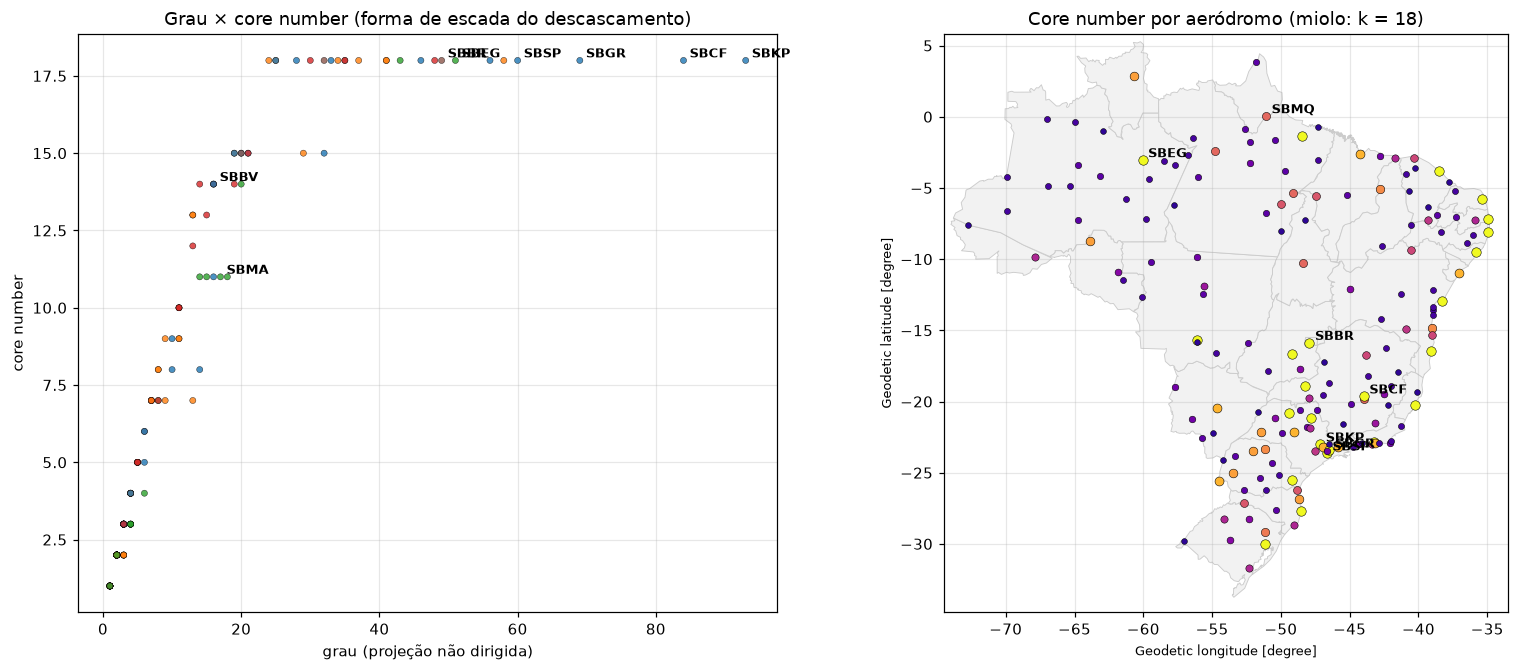

miolo (k = 18): 24 aeródromos -> SBKP, SBCF, SBGR, SBSP, SBRF, SBGL, SBEG, SBBR, SBCT, SBRP, SBBE, SBFZ, SBSV, SBPS, SBCY, SBPA, SBMO, SBVT, SBGO, SBFL, SBUL, SBJP, SBSR, SBSG
periferia (core number <= 2): 64 aeródromos


In [11]:
core = nx.core_number(h)
kcore = M.tabela_kcore(h)
kcore.to_csv(RESULTADOS / "kcore.csv", index=False)
degeneracao = max(core.values())
print("degeneração (maior core number):", degeneracao)
for k in [1, 2, 3, 5, 10, 15, degeneracao]:
    print(f"  k={k:2d}: {nx.k_core(h, k).number_of_nodes():3d} nós")

fig, eixos = plt.subplots(1, 2, figsize=(15, 6.2), gridspec_kw={"width_ratios": [1, 1.15]})
eixos[0].scatter(kcore.grau, kcore.core_number, s=16, c=[regioes[r] for r in kcore.regiao],
                 alpha=0.8, edgecolor="black", linewidth=0.3)
for icao in ["SBGR", "SBSP", "SBCF", "SBBR", "SBKP", "SBEG", "SBMA", "SBBV"]:
    linha = kcore[kcore.icao == icao]
    if not linha.empty:
        eixos[0].annotate(icao, (linha.grau.iloc[0], linha.core_number.iloc[0]),
                          xytext=(4, 2), textcoords="offset points", fontsize=8.5, fontweight="bold")
eixos[0].set_title("Grau × core number (forma de escada do descascamento)")
eixos[0].set_xlabel("grau (projeção não dirigida)"); eixos[0].set_ylabel("core number")
M.fundo_mapa(eixos[1])
pos = M.posicoes(g)
cmap = plt.get_cmap("plasma")
for n in g:
    eixos[1].scatter(*pos[n], color=cmap(core[n] / degeneracao), s=13 + 1.4 * core[n],
                     edgecolor="black", linewidth=0.35, zorder=3)
for icao in ["SBGR", "SBSP", "SBCF", "SBBR", "SBKP", "SBEG", "SBMQ"]:
    eixos[1].annotate(icao, (pos[icao][0] + 0.4, pos[icao][1] + 0.2), fontsize=8.5, fontweight="bold")
eixos[1].set_title(f"Core number por aeródromo (miolo: k = {degeneracao})")
eixos[1].set_xlim(-74.5, -33.5); eixos[1].set_ylim(-34.8, 5.8); eixos[1].set_aspect(1.035)
fig.tight_layout()
fig.savefig(FIGURAS / "05_kcore.png", bbox_inches="tight")
plt.show()

miolo = kcore[kcore.core_number == degeneracao]
print(f"miolo (k = {degeneracao}): {len(miolo)} aeródromos -> {', '.join(miolo.icao)}")
print(f"periferia (core number <= 2): {(kcore.core_number <= 2).sum()} aeródromos")

O miolo do k-core tem **24 aeródromos** (hubs das cinco regiões + eixo SP–RJ–BSB); **64 dos 176** têm core number ≤ 2: um terço da malha fica na periferia do k-core, com pouca redundância local.

## 6. Redundância: Jaccard de vizinhança e esqueleto de volume

In [12]:
jv = M.jaccard_vizinhanca(h)
jv.to_csv(RESULTADOS / "jaccard_vizinhanca.csv", index=False)
grandes = jv[(jv.grau_origem >= 8) & (jv.grau_destino >= 8)]
print(f"pares com grau >= 8 nas duas pontas: {len(grandes)}")
grandes.head(10).round(3)

pares com grau >= 8 nas duas pontas: 696


,origem,destino,grau_origem,grau_destino,vizinhos_comuns,vizinhos_uniao,jaccard,decolagens
7,SBGL,SBGR,56,69,52,71,0.732,10539.0
8,SBBR,SBGL,49,56,43,60,0.717,4997.0
9,SBSP,SBGR,60,69,53,74,0.716,164.0
10,SBJU,SBPL,8,11,7,10,0.700,1.0
11,SBMO,SBJP,34,25,23,34,0.676,45.0
16,SBBR,SBGR,49,69,46,70,0.657,9930.0
17,SBKP,SBGR,93,69,62,98,0.633,717.0
18,SBSP,SBRP,60,46,40,64,0.625,2376.0
19,SBCF,SBGR,84,69,58,93,0.624,10686.0
20,SBJP,SBSG,25,24,18,29,0.621,8.0


**Jaccard de vizinhança** mede se as duas pontas de uma rota conectam "o mesmo mundo". O par `SBGL–SBGR` tem J = 0,73: se Galeão fecha, Guarulhos já fala com 52 dos 71 destinos das duas; a malha perde capacidade, mas a maior parte da conexão fica.

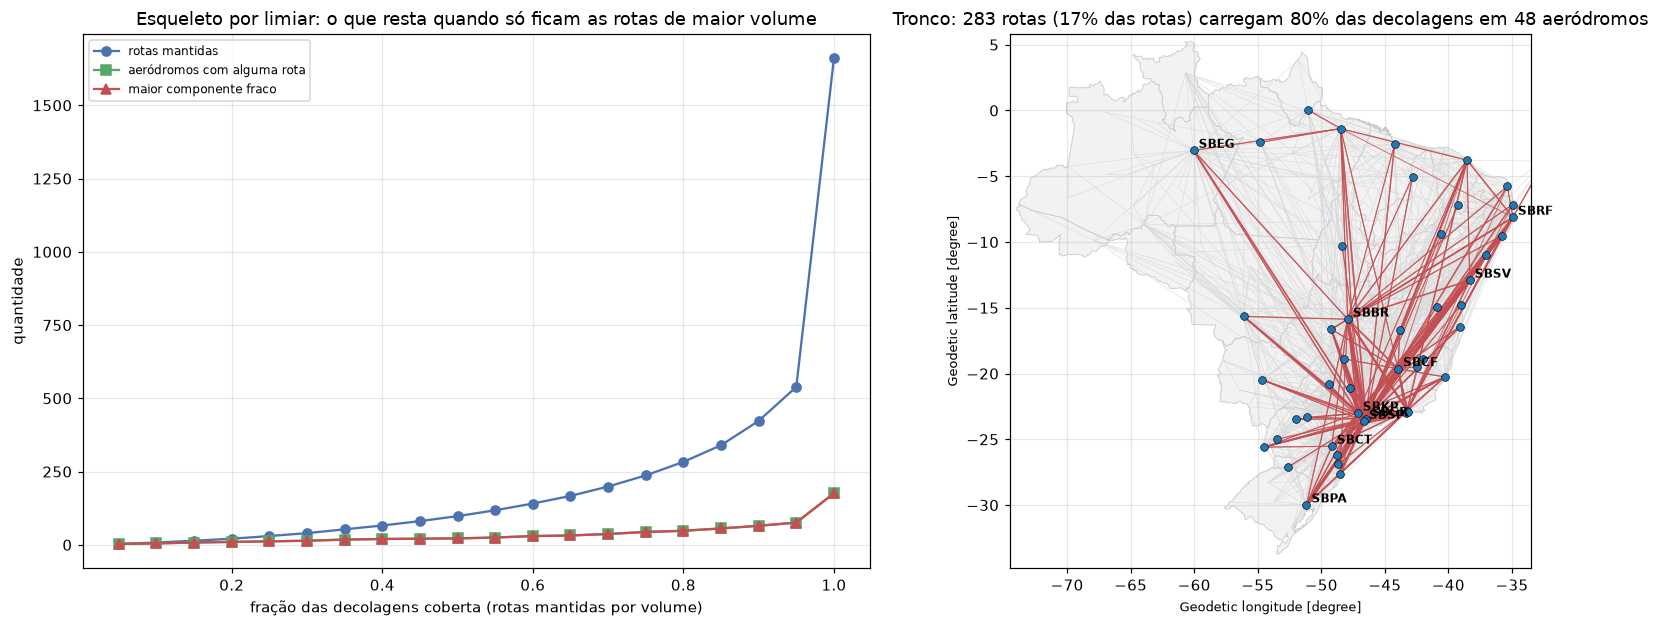

tronco em 80%: 283 rotas | 48 aeródromos (27% dos nós)


,fracao_alvo,fracao_real,arestas,nos,nos_com_conexao,componentes_fracos,maior_wcc,maior_scc,decolagens_cobertas
0,0.05,0.0563,3,176,3,174,3,2,45242.0
1,0.10,0.1074,8,176,5,172,5,5,86244.0
2,0.15,0.1558,14,176,8,169,8,8,125129.0
3,0.20,0.2015,21,176,10,167,10,10,161813.0
4,0.25,0.2540,30,176,12,165,12,11,203934.0
5,0.30,0.3006,40,176,14,163,14,12,241374.0
6,0.35,0.3534,53,176,18,159,18,17,283738.0
7,0.40,0.4019,66,176,20,157,20,18,322700.0
8,0.45,0.4503,81,176,21,156,21,21,361587.0
9,0.50,0.5001,98,176,22,155,22,22,401507.0


In [13]:
fracoes = [round(0.05 * i, 2) for i in range(1, 21)]  # 5% a 100%, passo de 5
esq = M.esqueleto_limiar(g, fracoes)
esq.to_csv(RESULTADOS / "esqueleto_limiar.csv", index=False)

fig, eixos = plt.subplots(1, 2, figsize=(15, 5.8), gridspec_kw={"width_ratios": [1.1, 1]})
eixos[0].plot(esq.fracao_alvo, esq.arestas, marker="o", color="#4c72b0", label="rotas mantidas")
eixos[0].plot(esq.fracao_alvo, esq.nos_com_conexao, marker="s", color="#55a868", label="aeródromos com alguma rota")
eixos[0].plot(esq.fracao_alvo, esq.maior_wcc, marker="^", color="#c44e52", label="maior componente fraco")
eixos[0].set_xlabel("fração das decolagens coberta (rotas mantidas por volume)")
eixos[0].set_ylabel("quantidade")
eixos[0].set_title("Esqueleto por limiar: o que resta quando só ficam as rotas de maior volume")
eixos[0].legend(fontsize=8)

arestas_ordenadas = sorted(g.edges(data=True), key=lambda e: -e[2]["decolagens"])
total_dec = sum(d["decolagens"] for _, _, d in arestas_ordenadas)
acumulado, tronco = 0.0, []
for u, v, d in arestas_ordenadas:
    if acumulado >= 0.8 * total_dec:
        break
    tronco.append((u, v, d))
    acumulado += d["decolagens"]
nos_tronco = sorted({x for u, v, _ in tronco for x in (u, v)})

M.fundo_mapa(eixos[1])
pos = M.posicoes(g)
for u, v, d in h.edges(data=True):
    eixos[1].plot([pos[u][0], pos[v][0]], [pos[u][1], pos[v][1]], color="#d9d9d9",
                  linewidth=0.35, zorder=1)
peso_max = max(d["decolagens"] for _, _, d in tronco)
for u, v, d in tronco:
    eixos[1].plot([pos[u][0], pos[v][0]], [pos[u][1], pos[v][1]], color="#c44e52",
                  alpha=0.75, linewidth=0.5 + 3.2 * d["decolagens"] / peso_max, zorder=2)
eixos[1].scatter([pos[n][0] for n in nos_tronco], [pos[n][1] for n in nos_tronco],
                 s=26, color="#1f77b4", edgecolor="black", linewidth=0.4, zorder=3)
for icao in ["SBGR", "SBSP", "SBKP", "SBCF", "SBBR", "SBSV", "SBRF", "SBEG", "SBPA", "SBCT"]:
    eixos[1].annotate(icao, (pos[icao][0] + 0.4, pos[icao][1] + 0.2), fontsize=8, fontweight="bold")
eixos[1].set_title(f"Tronco: {len(tronco)} rotas ({100 * len(tronco) / g.number_of_edges():.0f}% das rotas) "
                   f"carregam 80% das decolagens em {len(nos_tronco)} aeródromos")
eixos[1].set_xlim(-74.5, -33.5); eixos[1].set_ylim(-34.8, 5.8); eixos[1].set_aspect(1.035)
fig.tight_layout()
fig.savefig(FIGURAS / "06_esqueleto_limiar.png", bbox_inches="tight")
plt.show()

print(f"tronco em 80%: {len(tronco)} rotas | {len(nos_tronco)} aeródromos "
      f"({len(nos_tronco) / g.number_of_nodes():.0%} dos nós)")
esq.round(4)

O tronco é pequeno em rotas e enorme em volume: **283 rotas (17%) ligam 48 dos 176 aeródromos** e carregam 80% das decolagens. Mais de dois terços da malha ficam fora desse tronco e dependem das rotas de menor volume para estar conectados.

## 7. Pontes e articulações

Na projeção não dirigida, **pontos de corte** e **pontes** mostram a mesma fragilidade por outra ferramenta: nó/aresta cuja remoção separa a rede.

In [14]:
articulacoes = sorted(nx.articulation_points(h))
pontes = sorted(tuple(sorted(p)) for p in nx.bridges(h))
top20 = cent.sort_values("intermediacao", ascending=False).head(20).icao.tolist()
print(f"articulações: {len(articulacoes)} | pontes: {len(pontes)}")
print(f"do top-20 de intermediação, são articulações: {sum(a in articulacoes for a in top20)}")
print("articulações:", articulacoes)
print("primeiras pontes:", pontes[:8])

articulações: 18 | pontes: 22
do top-20 de intermediação, são articulações: 16
articulações: ['SBBE', 'SBCF', 'SBCT', 'SBCY', 'SBEG', 'SBFZ', 'SBGR', 'SBIH', 'SBJD', 'SBJR', 'SBKP', 'SBMA', 'SBPA', 'SBPJ', 'SBRB', 'SBRF', 'SBSJ', 'SBSV']
primeiras pontes: [('SBAC', 'SBRF'), ('SBBE', 'SNSM'), ('SBBP', 'SBSJ'), ('SBCF', 'SBVG'), ('SBCF', 'SNJM'), ('SBCF', 'SNLN'), ('SBCF', 'SNTO'), ('SBCF', 'SNZR')]


## 8. Análise de falha: o que acontece quando um aeródromo cai

Removemos cada aeródromo do top-10 em intermediação e do top-10 em volume e medimos: **fragmentação** (WCC), **alcance médio** (eficiência global) e **aeródromos que ficam sem rota de saída**.

In [15]:
top10_inter = cent.sort_values("intermediacao", ascending=False).head(10).icao.tolist()
top10_pax = cent.sort_values("passageiros_total", ascending=False).head(10).icao.tolist()
candidatos = list(dict.fromkeys(top10_inter + top10_pax))
impactos = pd.DataFrame([M.impacto_remocao(g, no) for no in candidatos])
impactos.to_csv(RESULTADOS / "falha_alvo.csv", index=False)
visao = impactos[["icao_removido", "componentes_depois", "perda_maior_wcc",
                  "aerodromos_sem_rota_saida", "perda_eficiencia_relativa"]].copy()
visao["perda_eficiencia_relativa"] = (100 * visao.perda_eficiencia_relativa).round(2)
visao = visao.sort_values("perda_eficiencia_relativa", ascending=False).reset_index(drop=True)
visao.columns = ["aeródromo", "componentes após", "perda do maior componente (nós)",
                 "sem rota de saída", "perda de eficiência (%)"]
visao

,aeródromo,componentes após,perda do maior componente (nós),sem rota de saída,perda de eficiência (%)
0,SBEG,5,8,3,10.27
1,SBCF,6,6,7,8.78
2,SBKP,2,2,3,8.52
3,SBRF,2,2,5,6.36
4,SBFZ,4,4,4,3.74
5,SBBE,2,2,2,3.21
6,SBSV,2,4,0,3.19
7,SBJD,2,3,0,2.42
8,SBCT,2,2,2,2.03
9,SBGR,2,2,1,1.82


A ordem de gravidade **não** é a dos maiores aeroportos: **crítico = único, não maior**. Manaus derruba 10,3% da eficiência e fragmenta em 5 componentes; Guarulhos, o maior em passageiros, custa 1,8%; tem alternativas.

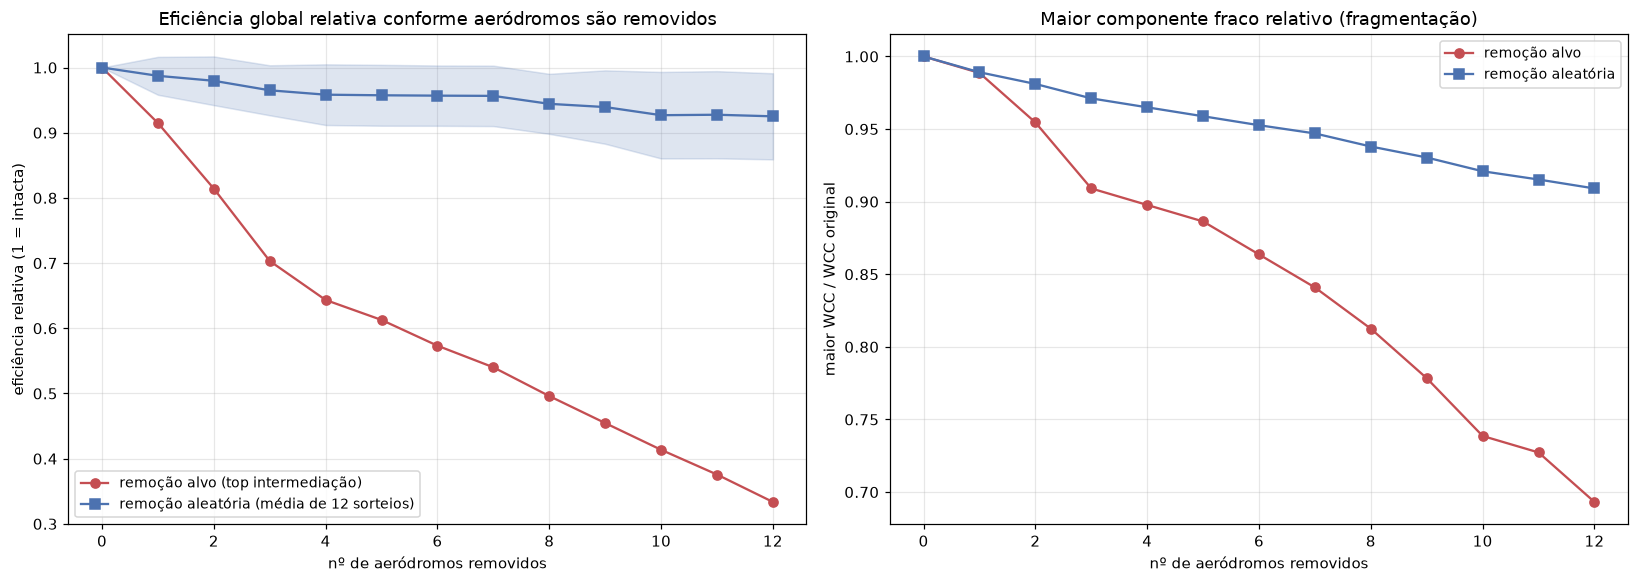

,k,eficiencia_alvo,wcc_alvo,eficiencia_aleatoria,eficiencia_aleatoria_desvio,wcc_aleatorio
0,0,1.000,1.000,1.000,0.000,1.000
1,1,0.915,0.989,0.987,0.029,0.989
2,2,0.814,0.955,0.980,0.037,0.981
3,3,0.703,0.909,0.965,0.038,0.971
4,4,0.643,0.898,0.958,0.047,0.965
5,5,0.613,0.886,0.957,0.047,0.959
6,6,0.573,0.864,0.957,0.046,0.953
7,7,0.540,0.841,0.956,0.046,0.947
8,8,0.496,0.812,0.944,0.046,0.938
9,9,0.455,0.778,0.939,0.056,0.930


In [16]:
curva_alvo = M.curva_remocao_alvo(g, cent.sort_values("intermediacao", ascending=False).icao.tolist(), k_max=12)
curva_aleatoria = M.curva_remocao_aleatoria(g, k_max=12, sorteios=12, seed=42)
comparacao_curvas = curva_alvo[["k", "eficiencia_relativa", "maior_wcc_relativo"]].rename(
    columns={"eficiencia_relativa": "eficiencia_alvo", "maior_wcc_relativo": "wcc_alvo"}).merge(
    curva_aleatoria.rename(columns={"eficiencia_relativa_media": "eficiencia_aleatoria",
                                    "eficiencia_relativa_desvio": "eficiencia_aleatoria_desvio",
                                    "maior_wcc_relativo_medio": "wcc_aleatorio"})
    [["k", "eficiencia_aleatoria", "eficiencia_aleatoria_desvio", "wcc_aleatorio"]], on="k", how="left")
comparacao_curvas.loc[comparacao_curvas.k == 0, ["eficiencia_aleatoria",
                                                 "eficiencia_aleatoria_desvio", "wcc_aleatorio"]] = [1.0, 0.0, 1.0]
comparacao_curvas.to_csv(RESULTADOS / "falha_curvas.csv", index=False)

fig, eixos = plt.subplots(1, 2, figsize=(15, 5.4))
eixos[0].plot(comparacao_curvas.k, comparacao_curvas.eficiencia_alvo, marker="o",
              color="#c44e52", label="remoção alvo (top intermediação)")
eixos[0].plot(comparacao_curvas.k, comparacao_curvas.eficiencia_aleatoria, marker="s",
              color="#4c72b0", label="remoção aleatória (média de 12 sorteios)")
eixos[0].fill_between(comparacao_curvas.k,
                      comparacao_curvas.eficiencia_aleatoria - comparacao_curvas.eficiencia_aleatoria_desvio,
                      comparacao_curvas.eficiencia_aleatoria + comparacao_curvas.eficiencia_aleatoria_desvio,
                      color="#4c72b0", alpha=0.18)
eixos[0].set_title("Eficiência global relativa conforme aeródromos são removidos")
eixos[0].set_xlabel("nº de aeródromos removidos"); eixos[0].set_ylabel("eficiência relativa (1 = intacta)")
eixos[0].legend(fontsize=9)
eixos[1].plot(comparacao_curvas.k, comparacao_curvas.wcc_alvo, marker="o", color="#c44e52", label="remoção alvo")
eixos[1].plot(comparacao_curvas.k, comparacao_curvas.wcc_aleatorio, marker="s", color="#4c72b0", label="remoção aleatória")
eixos[1].set_title("Maior componente fraco relativo (fragmentação)")
eixos[1].set_xlabel("nº de aeródromos removidos"); eixos[1].set_ylabel("maior WCC / WCC original")
eixos[1].legend(fontsize=9)
fig.tight_layout()
fig.savefig(FIGURAS / "07_falha_curvas.png", bbox_inches="tight")
plt.show()
comparacao_curvas.round(3)

Não é robusta a falha escolhida (12 remoções alvo derrubam a eficiência para ~1/3) e é tolerante a falha aleatória (~7% com 12 remoções): a malha tem **alvos preferenciais**.

In [17]:
ac = M.arestas_criticas(g, k=15)
ac.to_csv(RESULTADOS / "arestas_criticas.csv", index=False)
ac[["origem", "destino", "intermediacao_aresta", "decolagens", "conecta_sem_aresta",
    "saltos_sem_aresta", "ponte_na_projecao"]].round(4)

,origem,destino,intermediacao_aresta,decolagens,conecta_sem_aresta,saltos_sem_aresta,ponte_na_projecao
0,SBKP,SBEG,0.0140,1953.0,True,2.0,False
1,SBEG,SBKP,0.0127,2029.0,True,2.0,False
2,SBCF,SBEG,0.0118,399.0,True,2.0,False
3,SBEG,SBUY,0.0113,465.0,False,NaN,False
4,SBTT,SBEG,0.0113,496.0,False,NaN,False
5,SBEG,SBCF,0.0101,395.0,True,2.0,False
6,SBKP,SBBE,0.0094,1151.0,True,2.0,False
7,SBEG,SBIH,0.0092,157.0,True,2.0,False
8,SBRF,SBEG,0.0087,574.0,True,2.0,False
9,SBIH,SBEG,0.0084,157.0,True,3.0,False


O topo da intermediação de aresta é um único tema: **todas as 15 rotas do topo envolvem Manaus** (`SBKP↔SBEG` lidera nas duas direções). Nenhuma das 15 é ponte, e quase todas têm alternativa de +1 salto, mas duas relações direcionais perdem o caminho por completo (`SBEG→SBUY`, `SBTT→SBEG`).

SBKP fora: 5009 pares usavam o aeródromo
  perdem ligação total: 1545 (31%) | com alternativa: 3464 (desvio médio 0.81 salto)
SBEG fora: 5874 pares usavam o aeródromo
  perdem ligação total: 3374 (57%) | com alternativa: 2500 (desvio médio 0.39 salto)


exemplo: SWTP -> SBEK (3 -> 6.0 saltos)


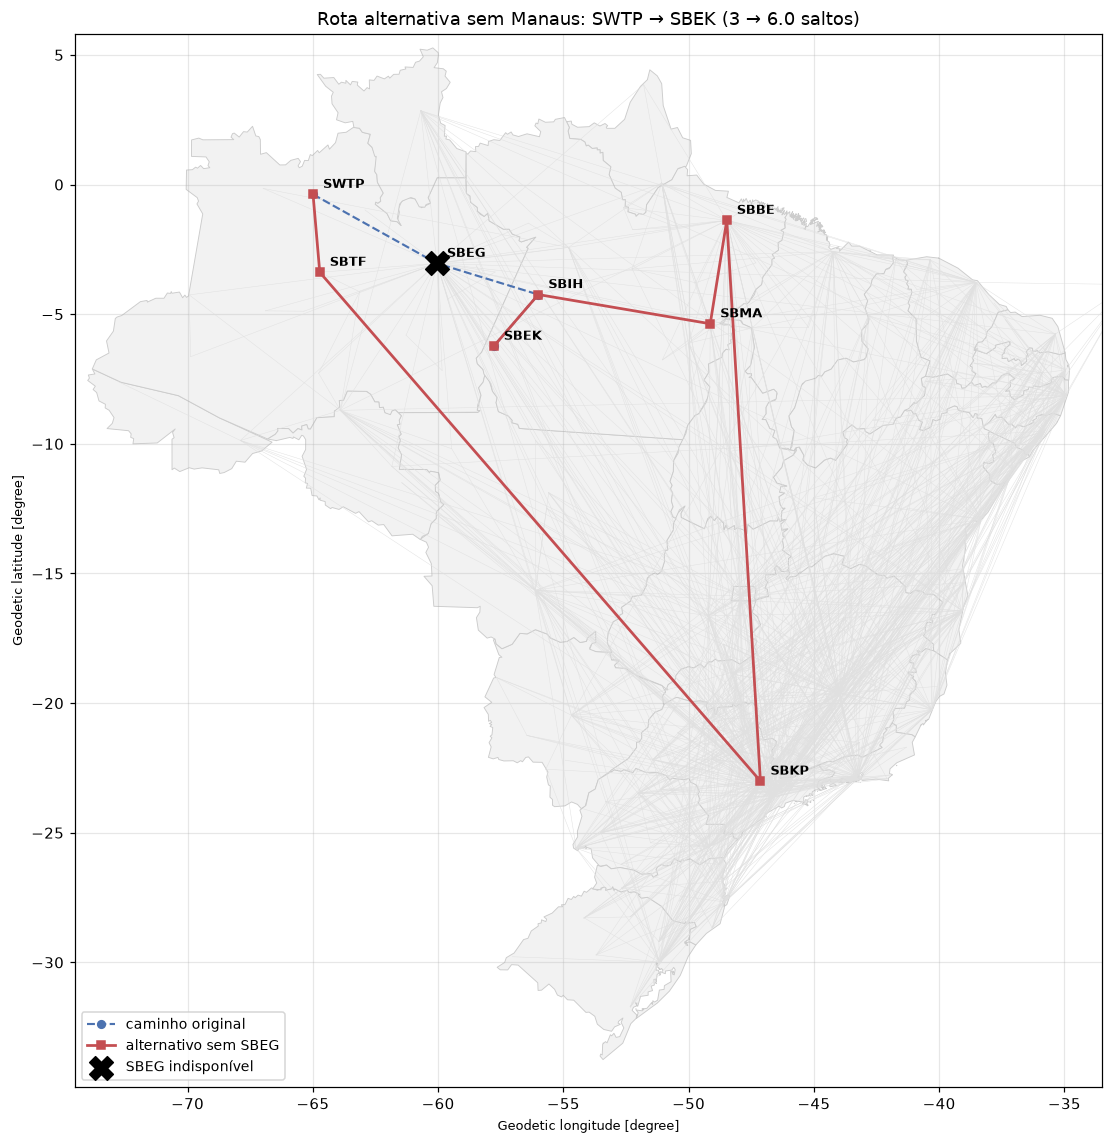

In [18]:
for no in ["SBKP", "SBEG"]:
    pares = M.pares_afetados(g, no=no)
    pares.to_csv(RESULTADOS / f"rotas_alternativas_{no}.csv", index=False)
    com = pares[pares.sobrou_caminho]
    print(f"{no} fora: {len(pares)} pares usavam o aeródromo")
    print(f"  perdem ligação total: {(~pares.sobrou_caminho).sum()} "
          f"({(~pares.sobrou_caminho).mean():.0%}) | com alternativa: {len(com)} "
          f"(desvio médio {com.delta_saltos.mean():.2f} salto)")

pares_sbeg = M.pares_afetados(g, no="SBEG")
exemplo = pares_sbeg[pares_sbeg.sobrou_caminho].nlargest(1, "delta_saltos").iloc[0]
caminho_antes = exemplo.caminho_antes.split(" -> ")
caminho_depois = exemplo.caminho_depois.split(" -> ")
print(f"exemplo: {exemplo.origem} -> {exemplo.destino} "
      f"({exemplo.saltos_antes} -> {exemplo.saltos_depois} saltos)")

fig, eixo = plt.subplots(figsize=(11, 10.5))
M.fundo_mapa(eixo)
pos = M.posicoes(g)
for u, v in h.edges():
    eixo.plot([pos[u][0], pos[v][0]], [pos[u][1], pos[v][1]], color="#e0e0e0", linewidth=0.3, zorder=1)
eixo.plot([pos[n][0] for n in caminho_antes], [pos[n][1] for n in caminho_antes],
          "--o", color="#4c72b0", linewidth=1.4, markersize=5, label="caminho original", zorder=3)
eixo.plot([pos[n][0] for n in caminho_depois], [pos[n][1] for n in caminho_depois],
          "-s", color="#c44e52", linewidth=1.8, markersize=5.5, label="alternativo sem SBEG", zorder=4)
eixo.scatter(*pos["SBEG"], marker="X", s=240, color="black", zorder=5, label="SBEG indisponível")
for n in set(caminho_antes) | set(caminho_depois):
    eixo.annotate(n, (pos[n][0] + 0.4, pos[n][1] + 0.25), fontsize=8.5, fontweight="bold", zorder=6)
eixo.set_title(f"Rota alternativa sem Manaus: {exemplo.origem} → {exemplo.destino} "
               f"({exemplo.saltos_antes} → {exemplo.saltos_depois} saltos)")
eixo.set_xlim(-74.5, -33.5); eixo.set_ylim(-34.8, 5.8); eixo.set_aspect(1.035)
eixo.legend(loc="lower left", fontsize=9)
fig.tight_layout()
fig.savefig(FIGURAS / "08_rota_alternativa.png", bbox_inches="tight")
plt.show()

## 9. Ranking de criticidade

Cruzamento das medidas (intermediação, core number, perda de eficiência medida e aeródromos sem rota de saída) no produto que a pergunta pede.

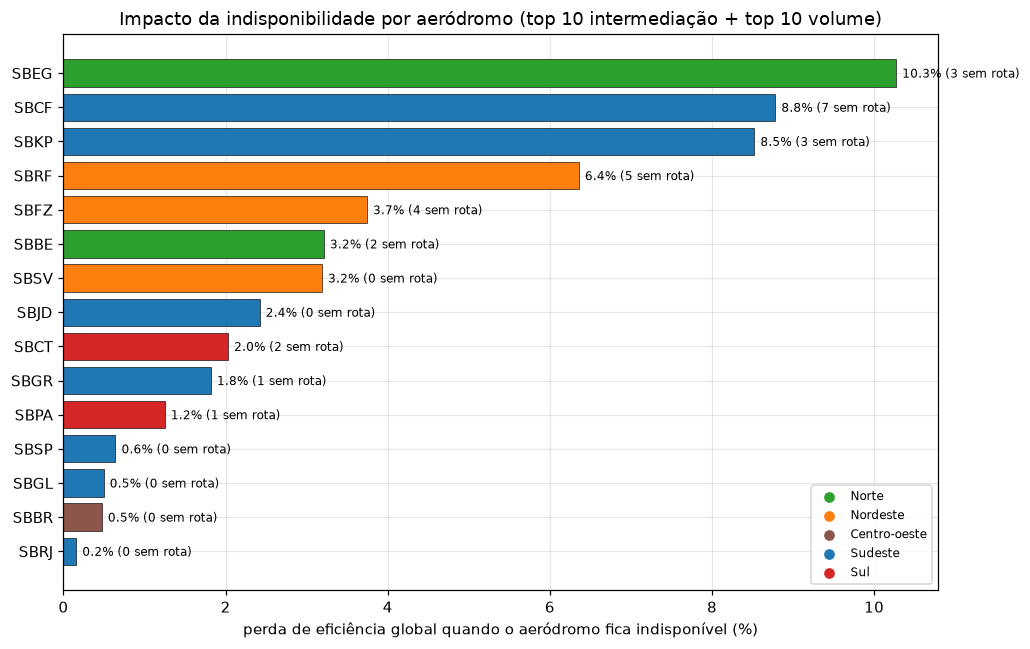

,icao,nome,uf,regiao,grau_total,passageiros_total,intermediacao,core_number,perda_eficiencia_relativa,aerodromos_sem_rota_saida
0,SBKP,CAMPINAS,SP,SUDESTE,181,11654910.0,0.2519,18,0.0852,3.0
1,SBCF,CONFINS,MG,SUDESTE,156,12339499.0,0.1997,18,0.0878,7.0
2,SBEG,MANAUS,AM,NORTE,90,2961478.0,0.1805,18,0.1027,3.0
3,SBRF,RECIFE,PE,NORDESTE,108,9242285.0,0.1169,18,0.0636,5.0
4,SBBE,BELÉM,PA,NORTE,76,3714377.0,0.0923,18,0.0321,2.0
5,SBGR,GUARULHOS,SP,SUDESTE,134,29872406.0,0.0746,18,0.0182,1.0
6,SBFZ,FORTALEZA,CE,NORDESTE,73,5556875.0,0.0567,18,0.0374,4.0
7,SBCT,SÃO JOSÉ DOS PINHAIS,PR,SUL,84,5846695.0,0.0513,18,0.0203,2.0
8,SBSV,SALVADOR,BA,NORDESTE,76,7304233.0,0.0505,18,0.0319,0.0
9,SBJD,JUNDIAÍ,SP,SUDESTE,50,0.0,0.0454,15,0.0242,0.0


In [19]:
ranking = (cent.merge(kcore[["icao", "core_number"]], on="icao")
           .merge(impactos[["icao_removido", "perda_eficiencia_relativa", "aerodromos_sem_rota_saida",
                            "lista_sem_rota_saida"]].rename(columns={"icao_removido": "icao"}),
                  on="icao", how="left"))
ranking["testado"] = ranking.icao.isin(candidatos)
ranking["top10_intermediacao"] = ranking.icao.isin(top10_inter)
ranking = ranking.sort_values("intermediacao", ascending=False).reset_index(drop=True)
ranking.to_csv(RESULTADOS / "ranking_criticidade.csv", index=False)

fig, eixo = plt.subplots(figsize=(9.5, 6))
presentes = impactos.sort_values("perda_eficiencia_relativa", ascending=True)
cores_barras = [regioes[r] for r in cent.set_index("icao").loc[presentes.icao_removido, "regiao"]]
eixo.barh(presentes.icao_removido, 100 * presentes.perda_eficiencia_relativa,
          color=cores_barras, edgecolor="black", linewidth=0.4)
for icao, valor, sem_rota in zip(presentes.icao_removido, 100 * presentes.perda_eficiencia_relativa,
                                 presentes.aerodromos_sem_rota_saida):
    eixo.annotate(f"{valor:.1f}% ({sem_rota} sem rota)", (valor, icao), xytext=(4, -3),
                  textcoords="offset points", fontsize=8)
for regiao, cor in regioes.items():
    eixo.scatter([], [], color=cor, label=regiao.capitalize())
eixo.set_xlabel("perda de eficiência global quando o aeródromo fica indisponível (%)")
eixo.set_title("Impacto da indisponibilidade por aeródromo (top 10 intermediação + top 10 volume)")
eixo.legend(fontsize=8, loc="lower right")
fig.tight_layout()
fig.savefig(FIGURAS / "09_ranking_criticidade.png", bbox_inches="tight")
plt.show()

ranking.head(12)[["icao", "nome", "uf", "regiao", "grau_total", "passageiros_total", "intermediacao",
                  "core_number", "perda_eficiencia_relativa", "aerodromos_sem_rota_saida"]].round(4)

## 10. Resposta à pergunta

**1. Aeródromos críticos.** `SBKP` (Campinas, intermediação 0,25), `SBCF` (Confins, 0,20) e `SBEG` (Manaus, 0,18). A distinção importa: por **passagem**, Campinas lidera; por **efeito medido**, Manaus lidera (10,3% da eficiência, 5 componentes, 3 aeródromos sem rota de saída). Confins tira 8,8% e deixa 7 sem rota de saída; Campinas, 8,5% e 3. Os grandes terminais fora dos três gargalos (SBGR, SBSP, SBBR, SBGL) custam no máximo 1,9%.

**2. Rotas críticas.** O corredor `SBKP↔SBEG` lidera a intermediação de aresta nas duas direções; todas as 15 rotas do topo envolvem Manaus. Nenhuma das 15 é ponte, mas `SBEG→SBUY` e `SBTT→SBEG` perdem o caminho por completo sem ela.

**3. Alternativas que restam.** Em Campinas, quem tem alternativa alonga até +2 saltos; em Confins, até +3. Para o Norte (SBEG), **57% dos pares não têm alternativa nenhuma**; entre os que têm, a maioria mantém o número de saltos ou alonga um, e o pior caso vai de 3 a 6 saltos (passando por Tefé, Campinas, Belém, Marabá e Itaituba).

**Em uma frase:** na rede, *crítico é o único, não o maior*: a malha tolera a queda dos grandes terminais e não tolera a queda dos portões regionais e das rotas de passagem.

## 11. Limitações do modelo

1. **Demanda reprimida.** A análise usa dados operados: não contabiliza trechos sem voos operantes por falta de infraestrutura.
2. **Dinâmica temporal.** Dados agregados anualmente escondem sazonalidades de alta temporada e picos diários.
3. **Conexões de passageiros.** Não mapeia a bilhetagem de ponta a ponta (*origin–destination true passenger itineraries*).